In [1]:
%load_ext autoreload
%autoreload 2

# Regression models

Here, we run all our regression models so that we can compare them side-by-side. We compare a dummy model and simple linear model to linear models with two regularization strategies (ridge and lasso), a decision tree model, a random forest model, and a boosted regression tree model. Hyperparameters are tuned with GridSearchCV or RandomizedSearchCV in each set of training folds, holding one whole fold out at the time, so the test fold is never used for tuning. We also run our models on several different splits to understand the limits of our models.

In [2]:
'''Import all relevant modules here and define root directory.'''

# Define root directory
import sys
from pathlib import Path

cwd = Path.cwd()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / ".git").exists())
sys.path.insert(0, str(ROOT))

# Modules imported from outside
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Modules internal to this project
from src.models.evaluate import CONFIGS, run_models, tuned, all_features, linear_features, load_predictions
from src.evaluation.results_log import load_runs, summarize

The following cell is used to set up necessary variables and define the parameter grids used for hyperparameter tuning.

In [3]:
RMSE = "neg_root_mean_squared_error"    # Scoring method
TREE_DEPTHS = [2, 3, 4, 5, 6, 8, 10, 15]    # For the decision tree model 
RF_GRID = {
    "max_depth": [6, 8, 11, 15, None], 
    "max_features": ["sqrt", 0.3, 0.5], 
    "min_samples_leaf": [1, 5, 20]
}   # For the random forest model
BRT_GRID = {
    "learning_rate": [0.03, 0.05], 
    "n_estimators": [20, 35, 50, 75, 100], 
    "max_depth": [2, 3, 4], 
    "min_child_weight": [5, 20, 50], 
    "subsample": [0.5, 0.7]
} # For the boosted regression tree model

In [4]:
def linear_pipe(model):
    """Impute and standardize inside each training fold, then fit the linear model."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)

The following cell contains our list of regression models.

In [5]:
REGRESSION_MODELS = {
    "Dummy (mean)": ("Team", lambda: DummyRegressor(strategy="mean"), all_features),
    "Linear regression": ("Andrea", lambda: linear_pipe(LinearRegression()), linear_features),
    "Ridge": ("Andrea", lambda: tuned(linear_pipe(Ridge()), {"ridge__alpha": np.logspace(0, 6, 13)}, RMSE), linear_features),
    "Lasso": ("Andrea", lambda: tuned(linear_pipe(Lasso(max_iter=20_000)), {"lasso__alpha": [0.001, 0.003, 0.01, 0.03, 0.1, 0.2, 0.3, 0.5]}, RMSE), linear_features),
    "Decision tree": ("Gavin", lambda: tuned(DecisionTreeRegressor(min_samples_leaf=20, random_state=0), {"max_depth": TREE_DEPTHS}, RMSE), all_features),
    "Random forest": ("Charlsey", lambda: tuned(RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=1), RF_GRID, RMSE, n_iter=10), all_features),
    "XGBoost BRT": ("Karuna", lambda: tuned(xgboost.XGBRegressor(objective="reg:squarederror", max_bin=64, random_state=0, n_jobs=1), BRT_GRID, RMSE, n_iter=20), all_features),
}

In [6]:
'''Run all models on each of the splits/configurations. Fold 4 in each split is set aside as the final hold-out.'''

RUN_MODELS = False    # True: refit every model (about 20 minutes per notebook); False: load the saved predictions

if RUN_MODELS:
    devs, oof = run_models(REGRESSION_MODELS, task="regression")
else:
    devs, oof = load_predictions("regression")


We now compare model performances across all configurations.

In [7]:
reg_runs = load_runs().query("task == 'regression'")
(reg_runs.groupby(["model", "split", "use_subbasin"])["rmse_log"].mean().unstack(["split", "use_subbasin"]).round(3))

split               10km        10km_subbasin 5km_subbasin 7.5km_subbasin
use_subbasin       False  True          True         True           True 
model                                                                    
Decision tree      1.161  1.048         1.060        1.068          1.031
Dummy (mean)       1.236  1.236         1.208        1.208          1.208
Lasso              1.146  1.119         1.016        1.031          1.033
Linear regression  1.179  1.141         1.045        1.021          1.058
Random forest      1.078  1.047         0.973        0.990          0.998
Ridge              1.142  1.100         1.031        1.033          1.040
XGBoost BRT        1.094  1.047         0.996        0.994          1.032

See model performance on the main configuration: 10km grid cells stratified along subbasin, with subbasin data included as a feature.

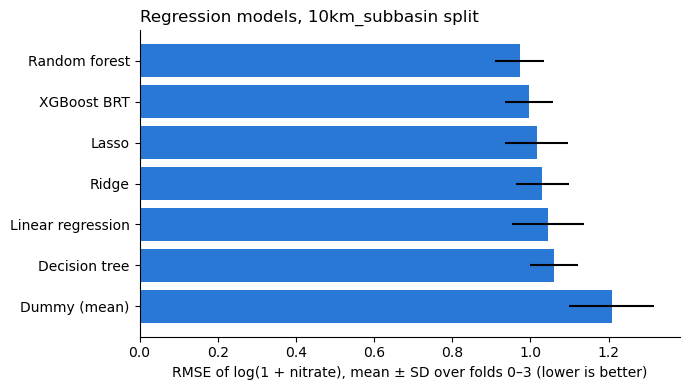

In [8]:
MAIN = ("10km_subbasin", True)

main = reg_runs[(reg_runs["split"] == MAIN[0]) & (reg_runs["use_subbasin"] == MAIN[1])]
by_model = main.groupby("model")["rmse_log"].agg(["mean", "std"]).sort_values("mean")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(by_model.index, by_model["mean"], xerr=by_model["std"], color="#2a78d6")
ax.invert_yaxis()                                   # best model on top
ax.set_xlabel("RMSE of log(1 + nitrate), mean ± SD over folds 0–3 (lower is better)")
ax.set_title(f"Regression models, {MAIN[0]} split", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(ROOT / "results" / "regression" / f"model_comparison_{MAIN[0]}.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
from sklearn.metrics import root_mean_squared_error, r2_score, roc_auc_score
from src.evaluation import splits, leakage

CONFIG = ("10km_subbasin", True)          # which configuration to plot
LOG_THRESHOLD = np.log1p(10)              # the 10 mg/L limit on the log scale
FIGURES = ROOT / "results" / "regression"
FIGURES.mkdir(parents=True, exist_ok=True)

dev = devs[CONFIG]
y_true = dev["log_nitrate"].to_numpy()
exceeds = dev["exceeds"].to_numpy().astype(bool)          # same labels as the classification notebook
folds = dev["fold"].to_numpy()
baseline = oof[("Dummy (mean)", *CONFIG)]                 # training-fold mean, for comparison
preds = {name: oof[(name, *CONFIG)] for name in REGRESSION_MODELS if not name.startswith("Dummy")}
TAG = f"{CONFIG[0]}, subbasin features={CONFIG[1]}"


def panels(n, ncols=3, width=4.5, height=3.8):
    """A grid with one panel per model; unused panels are hidden."""
    nrows = -(-n // ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(width * ncols, height * nrows), squeeze=False)
    axs = axs.ravel()
    for ax in axs[n:]:
        ax.set_axis_off()
    return fig, axs


def save(fig, name):
    fig.savefig(FIGURES / f"{name}_{CONFIG[0]}_subbasin{int(CONFIG[1])}.png", dpi=150, bbox_inches="tight")


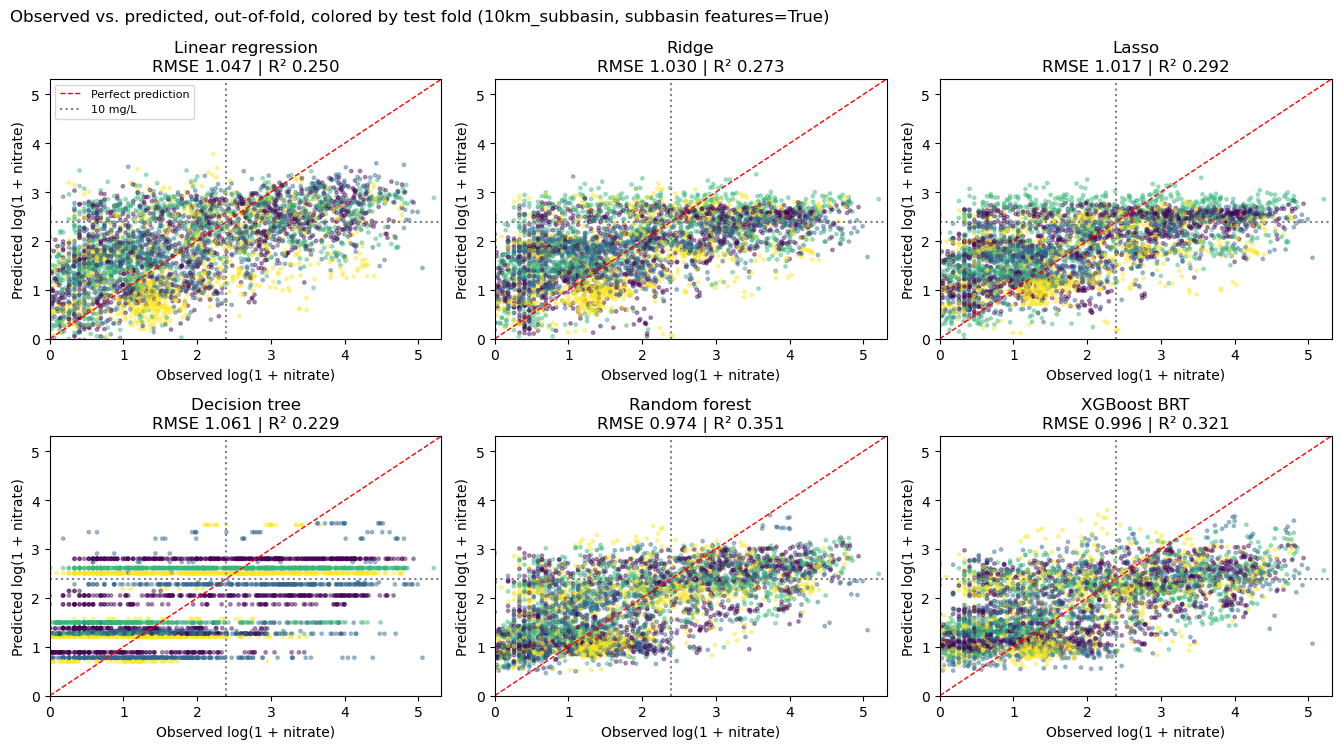

In [10]:
fig, axs = panels(len(preds))
lims = [0, y_true.max() * 1.02]
for ax, (name, pred) in zip(axs, preds.items()):
    ax.scatter(y_true, pred, c=folds, cmap="viridis", s=6, alpha=0.4)
    ax.plot(lims, lims, "r--", linewidth=1, label="Perfect prediction")
    ax.axvline(LOG_THRESHOLD, color="gray", linestyle=":", label="10 mg/L")
    ax.axhline(LOG_THRESHOLD, color="gray", linestyle=":")
    ax.set(title=f"{name}\nRMSE {root_mean_squared_error(y_true, pred):.3f} | R² {r2_score(y_true, pred):.3f}",
           xlabel="Observed log(1 + nitrate)", ylabel="Predicted log(1 + nitrate)", xlim=lims, ylim=lims)
axs[0].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Observed vs. predicted, out-of-fold, colored by test fold ({TAG})", x=0.01, ha="left")
plt.tight_layout()
save(fig, "observed_vs_predicted")
plt.show()


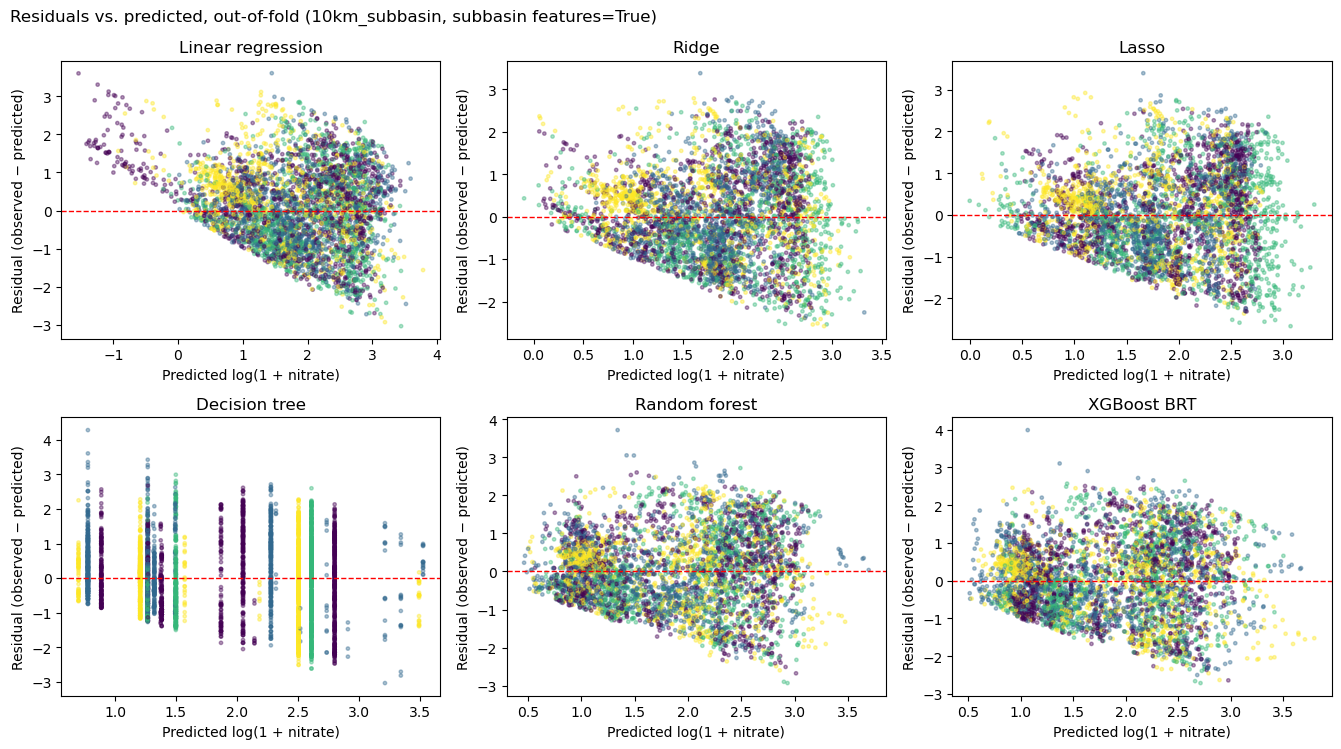

In [11]:
fig, axs = panels(len(preds))
for ax, (name, pred) in zip(axs, preds.items()):
    ax.scatter(pred, y_true - pred, c=folds, cmap="viridis", s=6, alpha=0.4)
    ax.axhline(0, color="red", linestyle="--", linewidth=1)
    ax.set(title=name, xlabel="Predicted log(1 + nitrate)", ylabel="Residual (observed − predicted)")
fig.suptitle(f"Residuals vs. predicted, out-of-fold ({TAG})", x=0.01, ha="left")
plt.tight_layout()
save(fig, "residuals")
plt.show()


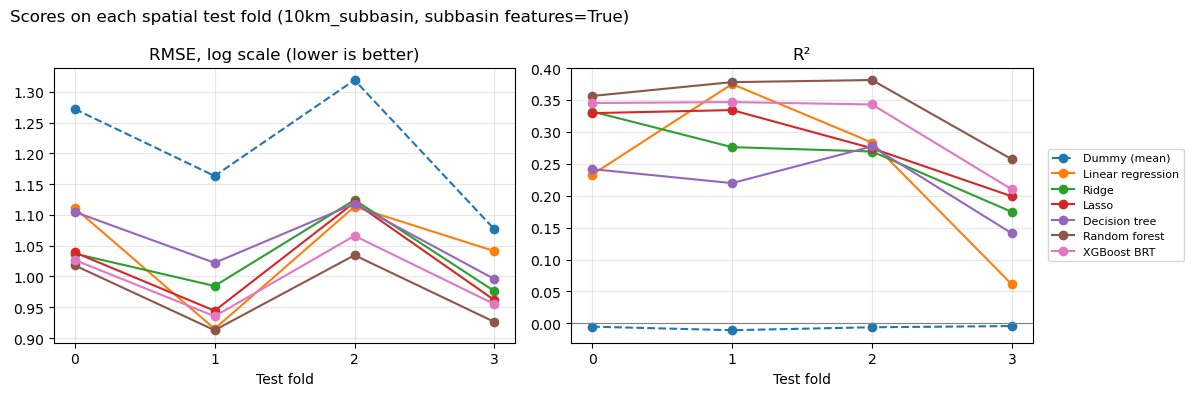

In [12]:
rows = []
for name, pred in {"Dummy (mean)": baseline, **preds}.items():
    for k in np.unique(folds):
        in_fold = folds == k
        rows.append({
            "model": name, "fold": k,
            "rmse_log": root_mean_squared_error(y_true[in_fold], pred[in_fold]),
            "r2": r2_score(y_true[in_fold], pred[in_fold])
        })
fold_metrics = pd.DataFrame(rows)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for name, group in fold_metrics.groupby("model", sort=False):
    style = "--" if name.startswith("Dummy") else "-"
    axs[0].plot(group["fold"], group["rmse_log"], style, marker="o", label=name)
    axs[1].plot(group["fold"], group["r2"], style, marker="o", label=name)
axs[0].set(title="RMSE, log scale (lower is better)", xlabel="Test fold", xticks=np.unique(folds))
axs[1].set(title="R²", xlabel="Test fold", xticks=np.unique(folds))
axs[1].axhline(0, color="gray", linewidth=0.8)
axs[1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5))
for ax in axs:
    ax.grid(alpha=0.3)
fig.suptitle(f"Scores on each spatial test fold ({TAG})", x=0.01, ha="left")
plt.tight_layout()
save(fig, "fold_metrics")
plt.show()


In [13]:
rows = []
for name, pred in preds.items():
    called = pred > LOG_THRESHOLD                  # predicted to exceed 10 mg/L
    rows.append({
        "model": name,
        "auc_from_prediction": roc_auc_score(exceeds, pred),
        "share_called_exceeding": called.mean(),
        "recall": called[exceeds].mean(),
        "precision": exceeds[called].mean() if called.any() else np.nan
    })
print(f"Actual share exceeding: {exceeds.mean():.3f}")
pd.DataFrame(rows).set_index("model").round(3)


Actual share exceeding: 0.319


,auc_from_prediction,share_called_exceeding,recall,precision
model,,,,
Linear regression,0.811,0.287,0.550,0.611
Ridge,0.801,0.239,0.463,0.617
Lasso,0.808,0.254,0.513,0.645
Decision tree,0.776,0.369,0.620,0.537
Random forest,0.839,0.259,0.543,0.668
XGBoost BRT,0.822,0.247,0.478,0.617


In [14]:
xy = leakage.projected_xy(dev, "gm_latitude", "gm_longitude")
nearest_m = np.full(len(dev), np.nan)
for train, test in splits.iter_folds(folds):
    nearest_m[test] = leakage.nearest_training_distance(xy, train, test)

breakdown = pd.concat({name: leakage.distance_breakdown(y_true, pred, baseline, nearest_m) for name, pred in preds.items()}, names=["model"])
display(breakdown["improvement_over_mean"].unstack("model"))
breakdown.xs(next(iter(preds)), level="model")[["n", "share_of_test"]]   # how many test samples per band


model,Linear regression,Ridge,Lasso,Decision tree,Random forest,XGBoost BRT
band,,,,,,
<0.5 km,0.356,0.268,0.278,0.351,0.421,0.401
0.5-1 km,0.128,0.103,0.122,0.097,0.181,0.133
1-2 km,0.163,0.159,0.164,0.146,0.195,0.171
2-5 km,0.135,0.162,0.170,0.111,0.191,0.169
>5 km,0.003,0.071,0.098,0.054,0.138,0.167


,n,share_of_test
band,,
<0.5 km,168,0.039
0.5-1 km,484,0.114
1-2 km,974,0.229
2-5 km,2019,0.474
>5 km,611,0.144


In [15]:
summarize(load_runs()).to_csv(ROOT / "results" / "model_comparison.csv")